<a href="https://colab.research.google.com/github/salpimentel/Time-Series/blob/main/Copy_of_L01_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
files.upload()

Saving cbe.dat to cbe.dat


{'cbe.dat': b'choc\tbeer\telec\n1451\t96.3\t1497\n2037\t84.4\t1463\n2477\t91.2\t1648\n2785\t81.9\t1595\n2994\t80.5\t1777\n2681\t70.4\t1824\n3098\t74.8\t1994\n2708\t75.9\t1835\n2517\t86.3\t1787\n2445\t98.7\t1699\n2087\t100.9\t1633\n1801\t113.8\t1645\n1216\t89.8\t1597\n2173\t84.4\t1577\n2286\t87.2\t1709\n3121\t85.6\t1756\n3458\t72\t1936\n3511\t69.2\t2052\n3524\t77.5\t2105\n2767\t78.1\t2016\n2744\t94.3\t1914\n2603\t97.7\t1925\n2527\t100.2\t1824\n1846\t116.4\t1765\n1066\t97.1\t1721\n2327\t93\t1752\n3066\t96\t1914\n3048\t80.5\t1857\n3806\t76.1\t2159\n4042\t69.9\t2195\n3583\t73.6\t2287\n3438\t92.6\t2276\n2957\t94.2\t2096\n2885\t93.5\t2055\n2744\t108.5\t2004\n1837\t109.4\t1924\n1447\t105.1\t1851\n2504\t92.5\t1839\n3248\t97.1\t2019\n3098\t81.4\t1937\n4318\t79.1\t2270\n3561\t72.1\t2251\n3316\t78.7\t2382\n3379\t87.1\t2364\n2717\t91.4\t2129\n2354\t109.9\t2110\n2445\t116.3\t2072\n1542\t113\t1980\n1606\t100\t1995\n2590\t84.8\t1932\n3588\t94.3\t2171\n3202\t87.1\t2162\n4704\t90.3\t2489\n4005\t72.4\t2

In [3]:
df_full = pd.read_csv("/content/cbe.dat", sep='\t')
df_full

,choc,beer,elec
0,1451,96.3,1497
1,2037,84.4,1463
2,2477,91.2,1648
3,2785,81.9,1595
4,2994,80.5,1777
...,...,...,...
391,8715,148.3,14338
392,8450,133.5,12867
393,9085,193.8,12761
394,8350,208.4,12449


In [4]:
df_full['Fecha'] = pd.period_range(start='1958-01', periods=len(df_full), freq='M')
df_full = df_full.set_index('Fecha')
df_full.head()

,choc,beer,elec
Fecha,,,
1958-01,1451,96.3,1497
1958-02,2037,84.4,1463
1958-03,2477,91.2,1648
1958-04,2785,81.9,1595
1958-05,2994,80.5,1777


In [5]:
# OJO!!!!!!!!!!!!!!
# Modifica el nombre de la columna por aquella que deseas analizar:

# Remplaza 'NOMBRE' por:

# 'choc' : Producción de bienes a base de chocolate (toneladas)
# 'beer' : Producción de cerveza (millones de litros)
# 'elec' : Producción de electricidad (millones de kWh)

df = df_full['elec'].to_frame()
df

,elec
Fecha,
1958-01,1497
1958-02,1463
1958-03,1648
1958-04,1595
1958-05,1777
...,...
1990-08,14338
1990-09,12867
1990-10,12761


In [6]:
df['promMovil'] = df['elec'].rolling(window=12).mean()

# Extraer el mes del índice para el gráfico de cajas
df['Mes'] = df.index.month

df.tail()

,elec,promMovil,Mes
Fecha,,,
1990-08,14338,12792.583333,8
1990-09,12867,12832.583333,9
1990-10,12761,12850.500000,10
1990-11,12449,12884.750000,11
1990-12,12658,12941.500000,12


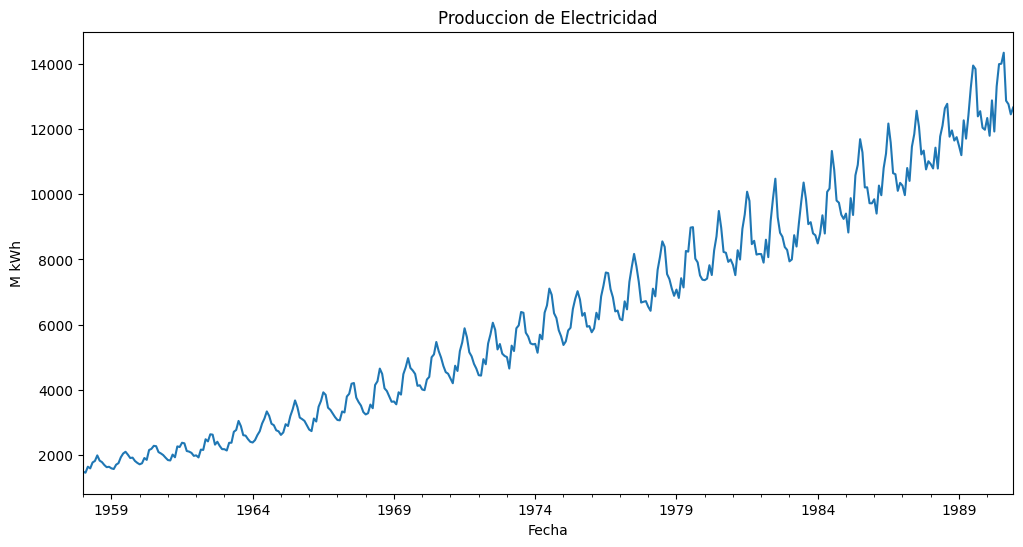

In [7]:
plt.figure(figsize=(12, 6))
df['elec'].plot()
plt.title('Produccion de Electricidad')
plt.xlabel('Fecha')
plt.ylabel('M kWh')
plt.show()

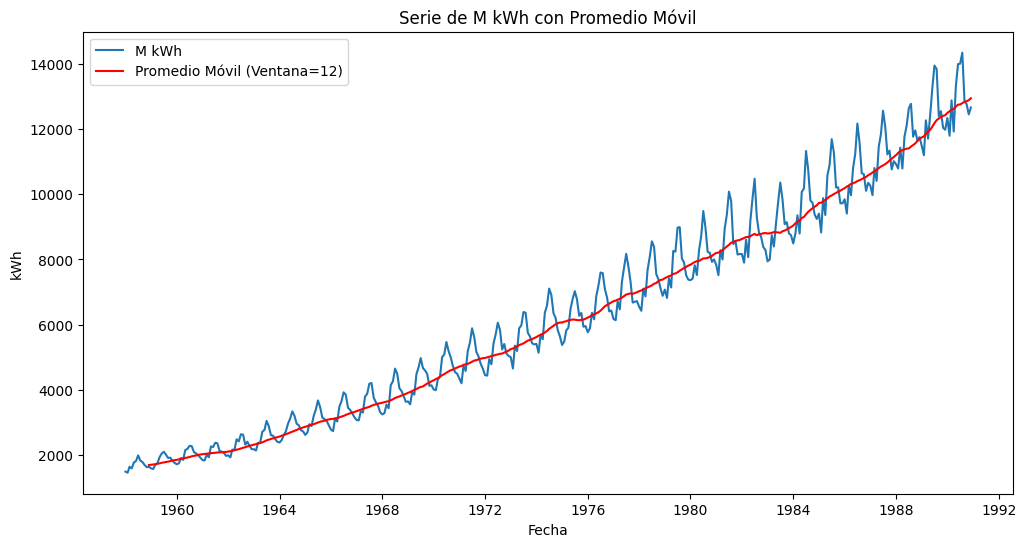

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(df['elec'].index.to_timestamp(), df['elec'], label='M kWh')
plt.plot(df['promMovil'].index.to_timestamp(), df['promMovil'], label='Promedio Móvil (Ventana=12)', color='red')
plt.title('Serie de M kWh con Promedio Móvil')
plt.xlabel('Fecha')
plt.ylabel('kWh')
plt.legend()

plt.show()

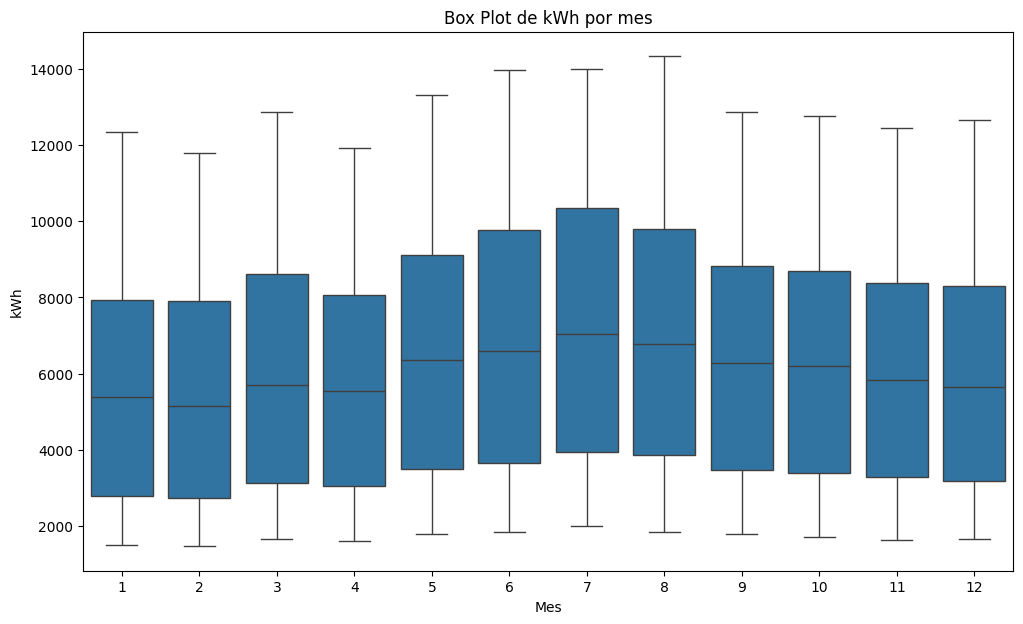

In [10]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Mes', y='elec', data=df)
plt.title('Box Plot de kWh por mes')
plt.xlabel('Mes')
plt.ylabel('kWh')
plt.show()